In [37]:
from google.colab import files

uploaded = files.upload()

Saving hotel_bookings.csv to hotel_bookings (1).csv


In [38]:
import pandas as pd
import io

filename = next(iter(uploaded))

df = pd.read_csv(io.BytesIO(uploaded[filename]))

print("Dataset shape:", df.shape)

df.head()

Dataset shape: (119390, 32)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [39]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

In [40]:
print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

Missing Values:
hotel                                  0
is_canceled                            0
lead_time                              0
arrival_date_year                      0
arrival_date_month                     0
arrival_date_week_number               0
arrival_date_day_of_month              0
stays_in_weekend_nights                0
stays_in_week_nights                   0
adults                                 0
children                               4
babies                                 0
meal                                   0
country                              488
market_segment                         0
distribution_channel                   0
is_repeated_guest                      0
previous_cancellations                 0
previous_bookings_not_canceled         0
reserved_room_type                     0
assigned_room_type                     0
booking_changes                        0
deposit_type                           0
agent                              16340


In [41]:
print(df["is_canceled"].value_counts())

print("\nCancellation Percentages:")
print(df["is_canceled"].value_counts(normalize=True) * 100)

is_canceled
0    75166
1    44224
Name: count, dtype: int64

Cancellation Percentages:
is_canceled
0    62.958372
1    37.041628
Name: proportion, dtype: float64


In [42]:
# Create a separate dataset without duplicate rows
df_dedup = df.drop_duplicates()

print("Original rows:", len(df))
print("Rows after removing duplicates:", len(df_dedup))
print("Rows removed:", len(df) - len(df_dedup))

# Compare cancellation percentages
original_rates = df["is_canceled"].value_counts(normalize=True) * 100

dedup_rates = df_dedup["is_canceled"].value_counts(normalize=True) * 100

comparison = pd.DataFrame({
    "Original (%)": original_rates,
    "Without Duplicates (%)": dedup_rates
})

display(comparison.round(2))

Original rows: 119390
Rows after removing duplicates: 87396
Rows removed: 31994


,Original (%),Without Duplicates (%)
is_canceled,,
0,62.96,72.51
1,37.04,27.49


In [43]:
# Select only rows flagged as duplicates
duplicates = df[df.duplicated()]

print("Total duplicate rows:", len(duplicates))

print("\nDuplicates by cancellation status:")
print(duplicates["is_canceled"].value_counts())

print("\nPercentage distribution:")
print(
    duplicates["is_canceled"]
    .value_counts(normalize=True) * 100
)

print("\nDuplicates by hotel type:")
print(
    pd.crosstab(
        duplicates["hotel"],
        duplicates["is_canceled"]
    )
)


Total duplicate rows: 31994

Duplicates by cancellation status:
is_canceled
1    20199
0    11795
Name: count, dtype: int64

Percentage distribution:
is_canceled
1    63.133713
0    36.866287
Name: proportion, dtype: float64

Duplicates by hotel type:
is_canceled      0      1
hotel                    
City Hotel    8849  17053
Resort Hotel  2946   3146


In [44]:
columns = ["children", "country", "agent", "company"]

for col in columns:

    print("\nColumn:", col)

    print(
        pd.crosstab(
            df[col].isnull(),
            df["is_canceled"],
            normalize="index"
        ) * 100
    )


Column: children
is_canceled          0           1
children                          
False        62.960481   37.039519
True          0.000000  100.000000

Column: country
is_canceled          0          1
country                          
False        62.862694  37.137306
True         86.270492  13.729508

Column: agent
is_canceled          0          1
agent                            
False        60.995633  39.004367
True         75.336597  24.663403

Column: company
is_canceled          0          1
company                          
False        82.477564  17.522436
True         61.780040  38.219960


In [45]:
# Keep the original dataset unchanged
df_prepared = df.copy()

# 1 if an agent is recorded, otherwise 0
df_prepared["has_agent"] = (
    df_prepared["agent"].notna().astype(int)
)

# 1 if a company is recorded, otherwise 0
df_prepared["has_company"] = (
    df_prepared["company"].notna().astype(int)
)

# Check the new columns
df_prepared[
    ["agent", "has_agent", "company", "has_company"]
].head(10)

,agent,has_agent,company,has_company
0,NaN,0,NaN,0
1,NaN,0,NaN,0
2,NaN,0,NaN,0
3,304.0,1,NaN,0
4,240.0,1,NaN,0
5,240.0,1,NaN,0
6,NaN,0,NaN,0
7,303.0,1,NaN,0
8,240.0,1,NaN,0
9,15.0,1,NaN,0


In [46]:
print("Agent indicator:")
print(df_prepared["has_agent"].value_counts())

print("\nCompany indicator:")
print(df_prepared["has_company"].value_counts())

Agent indicator:
has_agent
1    103050
0     16340
Name: count, dtype: int64

Company indicator:
has_company
0    112593
1      6797
Name: count, dtype: int64


In [47]:
# Define the features for our first model
features = [
    "hotel",
    "lead_time",
    "adr",
    "stays_in_week_nights",
    "stays_in_weekend_nights",
    "children",
    "previous_cancellations",
    "deposit_type",
    "country",
    "total_of_special_requests",
    "has_agent",
    "has_company"
]

# Start with the deduplicated version for our baseline experiment
df_model = df_prepared.drop_duplicates().copy()

# Separate features and target
X = df_model[features]
y = df_model["is_canceled"]

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

print("\nSelected features:")
print(X.columns.tolist())

print("\nClass distribution:")
print(y.value_counts(normalize=True) * 100)

Feature matrix shape: (87396, 12)
Target shape: (87396,)

Selected features:
['hotel', 'lead_time', 'adr', 'stays_in_week_nights', 'stays_in_weekend_nights', 'children', 'previous_cancellations', 'deposit_type', 'country', 'total_of_special_requests', 'has_agent', 'has_company']

Class distribution:
is_canceled
0    72.510184
1    27.489816
Name: proportion, dtype: float64


In [48]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

Training features: (69916, 12)
Testing features: (17480, 12)
Training labels: (69916,)
Testing labels: (17480,)


In [49]:
print("Training class percentages:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting class percentages:")
print(y_test.value_counts(normalize=True) * 100)

Training class percentages:
is_canceled
0    72.509869
1    27.490131
Name: proportion, dtype: float64

Testing class percentages:
is_canceled
0    72.511442
1    27.488558
Name: proportion, dtype: float64


In [50]:
train_hashes = pd.util.hash_pandas_object(
    X_train, index=False
)

test_hashes = pd.util.hash_pandas_object(
    X_test, index=False
)

overlap_count = test_hashes.isin(train_hashes).sum()

print("Test rows matching training feature patterns:", overlap_count)

Test rows matching training feature patterns: 1790


In [51]:
from sklearn.model_selection import StratifiedGroupKFold

# Preserve the original split for later comparison
X_train_basic, X_test_basic = X_train, X_test
y_train_basic, y_test_basic = y_train, y_test

# Assign identical feature rows to the same group
groups = pd.util.hash_pandas_object(
    X, index=False
)

# Create approximately 80/20 training and test sets
sgkf = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

train_idx, test_idx = next(
    sgkf.split(X, y, groups)
)

X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()

y_train = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Training shape: (70020, 12)
Testing shape: (17376, 12)


In [52]:
print("Training cancellation percentage:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting cancellation percentage:")
print(y_test.value_counts(normalize=True) * 100)

train_hashes = pd.util.hash_pandas_object(
    X_train, index=False
)

test_hashes = pd.util.hash_pandas_object(
    X_test, index=False
)

overlap = test_hashes.isin(train_hashes).sum()

print("\nOverlapping feature patterns:", overlap)

Training cancellation percentage:
is_canceled
0    72.549272
1    27.450728
Name: proportion, dtype: float64

Testing cancellation percentage:
is_canceled
0    72.35267
1    27.64733
Name: proportion, dtype: float64

Overlapping feature patterns: 0


In [53]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Numerical columns
numeric_features = [
    "lead_time",
    "adr",
    "stays_in_week_nights",
    "stays_in_weekend_nights",
    "children",
    "previous_cancellations",
    "total_of_special_requests",
    "has_agent",
    "has_company"
]

# Categorical columns
categorical_features = [
    "hotel",
    "deposit_type",
    "country"
]

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(
        strategy="constant",
        fill_value="Unknown"
    )),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

In [54]:
# Learn preprocessing parameters from training data
X_train_processed = preprocessor.fit_transform(X_train)

# Apply the same transformations to test data
X_test_processed = preprocessor.transform(X_test)

print("Original training shape:", X_train.shape)

print("Processed training shape:", X_train_processed.shape)

print("Processed testing shape:", X_test_processed.shape)

Original training shape: (70020, 12)
Processed training shape: (70020, 182)
Processed testing shape: (17376, 182)


In [55]:
from sklearn.linear_model import LogisticRegression

# Initialize Logistic Regression
log_reg = LogisticRegression(
    max_iter=1000,
    solver="liblinear",
    random_state=42
)

# Train the model
log_reg.fit(X_train_processed, y_train)

print("Logistic Regression training completed.")

Logistic Regression training completed.


In [56]:
# Predict cancellation classes
y_pred_log = log_reg.predict(X_test_processed)

# Predict cancellation probabilities
y_prob_log = log_reg.predict_proba(X_test_processed)[:, 1]

print("First 10 predicted classes:")
print(y_pred_log[:10])

print("\nFirst 10 cancellation probabilities:")
print(y_prob_log[:10])

First 10 predicted classes:
[0 0 0 0 0 1 0 0 0 0]

First 10 cancellation probabilities:
[0.2670039  0.05706902 0.44792458 0.38981113 0.41574272 0.53894091
 0.10987141 0.17049042 0.16255241 0.13757485]


In [57]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

print("Logistic Regression Results")

print("Accuracy:",
      round(accuracy_score(y_test, y_pred_log), 4))

print("Precision:",
      round(precision_score(y_test, y_pred_log), 4))

print("Recall:",
      round(recall_score(y_test, y_pred_log), 4))

print("F1-score:",
      round(f1_score(y_test, y_pred_log), 4))

print("ROC-AUC:",
      round(roc_auc_score(y_test, y_prob_log), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_log))

# Accuracy if we always predict "not canceled"
majority_baseline = (y_test == 0).mean()

print("\nMajority-class baseline accuracy:",
      round(majority_baseline, 4))

Logistic Regression Results
Accuracy: 0.7562
Precision: 0.6449
Recall: 0.2627
F1-score: 0.3733
ROC-AUC: 0.743

Confusion Matrix:
[[11877   695]
 [ 3542  1262]]

Majority-class baseline accuracy: 0.7235


In [58]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=16,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_processed, y_train)

print("Random Forest training completed.")

Random Forest training completed.


In [59]:
# Predictions
y_pred_rf = rf_model.predict(X_test_processed)

# Cancellation probabilities
y_prob_rf = rf_model.predict_proba(X_test_processed)[:, 1]

print("Random Forest Results")

print("Accuracy:",
      round(accuracy_score(y_test, y_pred_rf), 4))

print("Precision:",
      round(precision_score(y_test, y_pred_rf), 4))

print("Recall:",
      round(recall_score(y_test, y_pred_rf), 4))

print("F1-score:",
      round(f1_score(y_test, y_pred_rf), 4))

print("ROC-AUC:",
      round(roc_auc_score(y_test, y_prob_rf), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

Random Forest Results
Accuracy: 0.7635
Precision: 0.8349
Recall: 0.1801
F1-score: 0.2962
ROC-AUC: 0.8078

Confusion Matrix:
[[12401   171]
 [ 3939   865]]


In [60]:
comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],

    "Accuracy": [
        accuracy_score(y_test, y_pred_log),
        accuracy_score(y_test, y_pred_rf)
    ],

    "Precision": [
        precision_score(y_test, y_pred_log),
        precision_score(y_test, y_pred_rf)
    ],

    "Recall": [
        recall_score(y_test, y_pred_log),
        recall_score(y_test, y_pred_rf)
    ],

    "F1-score": [
        f1_score(y_test, y_pred_log),
        f1_score(y_test, y_pred_rf)
    ],

    "ROC-AUC": [
        roc_auc_score(y_test, y_prob_log),
        roc_auc_score(y_test, y_prob_rf)
    ]
})

comparison = comparison.set_index("Model")

display(comparison.round(4))

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Logistic Regression,0.7562,0.6449,0.2627,0.3733,0.7430
Random Forest,0.7635,0.8349,0.1801,0.2962,0.8078


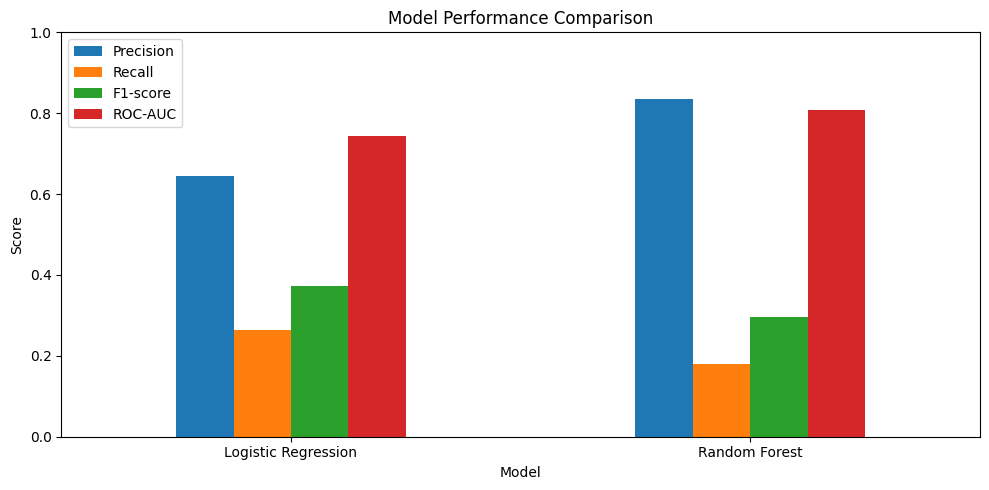

In [61]:
import matplotlib.pyplot as plt

comparison[
    ["Precision", "Recall", "F1-score", "ROC-AUC"]
].plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Model")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend()
plt.tight_layout()
plt.show()

In [62]:
from sklearn.model_selection import StratifiedGroupKFold

# Identify identical feature patterns within training data
train_groups = pd.util.hash_pandas_object(
    X_train,
    index=False
)

# Create training/validation folds
validation_splitter = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=123
)

fit_idx, val_idx = next(
    validation_splitter.split(
        X_train,
        y_train,
        groups=train_groups
    )
)

# Model-fitting data
X_fit = X_train.iloc[fit_idx].copy()
y_fit = y_train.iloc[fit_idx].copy()

# Validation data
X_val = X_train.iloc[val_idx].copy()
y_val = y_train.iloc[val_idx].copy()

print("Model fitting:", X_fit.shape)
print("Validation:", X_val.shape)

Model fitting: (56142, 12)
Validation: (13878, 12)


In [63]:
print("Model-fitting class distribution:")
print(y_fit.value_counts(normalize=True) * 100)

print("\nValidation class distribution:")
print(y_val.value_counts(normalize=True) * 100)

# Check overlapping feature patterns
fit_hashes = pd.util.hash_pandas_object(
    X_fit, index=False
)

val_hashes = pd.util.hash_pandas_object(
    X_val, index=False
)

overlap = val_hashes.isin(fit_hashes).sum()

print("\nOverlapping patterns:", overlap)

Model-fitting class distribution:
is_canceled
0    72.639022
1    27.360978
Name: proportion, dtype: float64

Validation class distribution:
is_canceled
0    72.186194
1    27.813806
Name: proportion, dtype: float64

Overlapping patterns: 0


In [64]:
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Two Logistic Regression configurations
configurations = {
    "Standard": None,
    "Balanced": "balanced"
}

validation_models = {}
validation_results = []

for name, weight in configurations.items():

    # Fresh preprocessing and classifier
    model = Pipeline(steps=[
        ("preprocessing", clone(preprocessor)),
        ("classifier", LogisticRegression(
            max_iter=1000,
            solver="liblinear",
            class_weight=weight,
            random_state=42
        ))
    ])

    # Train only on model-fitting data
    model.fit(X_fit, y_fit)

    # Evaluate on validation data
    predictions = model.predict(X_val)
    probabilities = model.predict_proba(X_val)[:, 1]

    validation_models[name] = model

    validation_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, predictions),
        "Precision": precision_score(y_val, predictions),
        "Recall": recall_score(y_val, predictions),
        "F1": f1_score(y_val, predictions),
        "ROC-AUC": roc_auc_score(y_val, probabilities)
    })

validation_comparison = pd.DataFrame(
    validation_results
).set_index("Model")

display(validation_comparison.round(4))

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Standard,0.7568,0.6540,0.2668,0.3790,0.7432
Balanced,0.6912,0.4622,0.6736,0.5482,0.7440


In [65]:
import numpy as np

# Use our balanced Logistic Regression model
balanced_model = validation_models["Balanced"]

# Get predicted probabilities
val_probabilities = balanced_model.predict_proba(X_val)[:, 1]

# Try different thresholds
thresholds = [0.3, 0.4, 0.5, 0.6, 0.7]

threshold_results = []

for threshold in thresholds:

    predictions = (
        val_probabilities >= threshold
    ).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_val, predictions, zero_division=0
        )
    })

threshold_comparison = pd.DataFrame(threshold_results)

display(threshold_comparison.round(4))

,Threshold,Precision,Recall,F1
0,0.3,0.3384,0.9187,0.4946
1,0.4,0.3938,0.8101,0.5300
2,0.5,0.4622,0.6736,0.5482
3,0.6,0.5191,0.5010,0.5099
4,0.7,0.6077,0.3166,0.4163


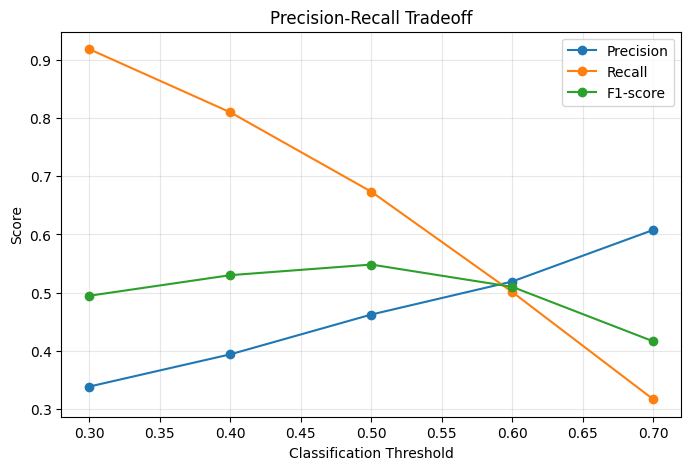

In [66]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    threshold_comparison["Threshold"],
    threshold_comparison["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_comparison["Threshold"],
    threshold_comparison["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_comparison["Threshold"],
    threshold_comparison["F1"],
    marker="o",
    label="F1-score"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Precision-Recall Tradeoff")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.base import clone
from sklearn.pipeline import Pipeline

rf_validation_models = {}
rf_validation_results = []

rf_configurations = {
    "RF Standard": None,
    "RF Balanced": "balanced"
}

for name, weight in rf_configurations.items():

    model = Pipeline(steps=[
        ("preprocessing", clone(preprocessor)),
        ("classifier", RandomForestClassifier(
            n_estimators=100,
            max_depth=16,
            min_samples_leaf=2,
            class_weight=weight,
            random_state=42,
            n_jobs=-1
        ))
    ])

    model.fit(X_fit, y_fit)

    predictions = model.predict(X_val)
    probabilities = model.predict_proba(X_val)[:, 1]

    rf_validation_models[name] = model

    rf_validation_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, predictions),
        "Precision": precision_score(y_val, predictions),
        "Recall": recall_score(y_val, predictions),
        "F1": f1_score(y_val, predictions),
        "ROC-AUC": roc_auc_score(y_val, probabilities)
    })

rf_validation_comparison = pd.DataFrame(
    rf_validation_results
).set_index("Model")

display(rf_validation_comparison.round(4))

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
RF Standard,0.7675,0.7930,0.2223,0.3472,0.8034
RF Balanced,0.7484,0.5368,0.6956,0.6060,0.8047


In [ ]:
all_validation_results = pd.concat([
    validation_comparison,
    rf_validation_comparison
])

display(all_validation_results.round(4))

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Standard,0.7568,0.6540,0.2668,0.3790,0.7432
Balanced,0.6912,0.4622,0.6736,0.5482,0.7440
RF Standard,0.7675,0.7930,0.2223,0.3472,0.8034
RF Balanced,0.7484,0.5368,0.6956,0.6060,0.8047


In [ ]:
!pip install -q streamlit

In [81]:
%%writefile app.py

import streamlit as st
import pandas as pd
from pathlib import Path

st.title("Hotel Booking Cancellation Dashboard")

st.write("Analysis of hotel booking cancellations")

# Load dataset
@st.cache_data
def load_data(file_path):
    return pd.read_csv(file_path)

possible_paths = [
    Path("hotel_bookings.csv"),
    Path("/content/hotel_bookings.csv")
]

data_path = next(
    (p for p in possible_paths if p.exists()),
    None
)

if data_path is None:
    st.warning("Dataset not found.")
    st.stop()

df = load_data(str(data_path))

# Sidebar
st.sidebar.header("Filters")

hotel_type = st.sidebar.selectbox(
    "Select Hotel Type",
    ["All"] + sorted(df["hotel"].unique().tolist())
)

max_lead_time = st.sidebar.slider(
    "Maximum Lead Time (Days)",
    min_value=0,
    max_value=int(df["lead_time"].max()),
    value=int(df["lead_time"].max())
)

# Apply filters
filtered_df = df.copy()

if hotel_type != "All":
    filtered_df = filtered_df[
        filtered_df["hotel"] == hotel_type
    ]

filtered_df = filtered_df[
    filtered_df["lead_time"] <= max_lead_time
]

# Display results
st.subheader("Dataset Overview")

st.write("Filtered Records:", len(filtered_df))

st.dataframe(filtered_df.head(10))

if filtered_df.empty:
    st.warning("No records match the selected filters.")
    st.stop()

# Cancellation rate
cancellation_rate = filtered_df["is_canceled"].mean() * 100

st.metric(
    "Cancellation Rate",
    f"{cancellation_rate:.2f}%"
)

# Chart
st.subheader("Cancellation Rate by Hotel")

hotel_rates = (
    filtered_df.groupby("hotel")["is_canceled"].mean() * 100
)

st.bar_chart(hotel_rates)

Overwriting app.py


In [78]:
from pathlib import Path

print("App exists:", Path("app.py").exists())

print("\nDataset locations:")
for file in Path("/content").rglob("hotel_bookings.csv"):
    print(file)

App exists: True

Dataset locations:
/content/hotel_bookings.csv


In [83]:
import subprocess
import sys
import time
from urllib.parse import urlsplit
from google.colab import output

# Get Colab's application address
proxy_url = output.eval_js(
    "google.colab.kernel.proxyPort(8501)"
)

parsed = urlsplit(proxy_url)
colab_origin = f"{parsed.scheme}://{parsed.netloc}"

# Stop the previous server if it is still running
if "server" in globals() and server.poll() is None:
    server.terminate()
    server.wait(timeout=10)

# Start Streamlit
server = subprocess.Popen(
    [
        sys.executable, "-m", "streamlit",
        "run", "app.py",
        "--server.port=8501",
        "--server.headless=true",
        f"--server.corsAllowedOrigins={colab_origin}"
    ],
    stdout=open("/content/streamlit.log", "w"),
    stderr=subprocess.STDOUT
)

time.sleep(5)

if server.poll() is None:
    print("Streamlit is running!")
else:
    print("Streamlit failed to start")
    print(Path("/content/streamlit.log").read_text()[-2000:])

Streamlit is running!


In [84]:
from google.colab import output

output.serve_kernel_port_as_iframe(
    8501,
    height="900"
)

<IPython.core.display.Javascript object>

In [86]:
%pip install -q \
    "langchain-google-genai==4.3.7" \
    "google-genai==2.12.1" \
    "google-auth==2.49.0"

In [87]:
from langchain_google_genai import ChatGoogleGenerativeAI
from google.colab import userdata

print("LangChain imported successfully!")

LangChain imported successfully!


In [89]:
from google.colab import userdata

api_key = userdata.get("GOOGLE_API_KEY")

if api_key:
    print("API key loaded successfully!")

API key loaded successfully!


In [91]:
import os
from google.colab import userdata
from langchain_google_genai import ChatGoogleGenerativeAI

# Get API key securely
os.environ["GOOGLE_API_KEY"] = userdata.get("GOOGLE_API_KEY")

# Initialize the language model
llm = ChatGoogleGenerativeAI(
    model="gemini-3.8-flash",
    temperature=0
)

# Send a question
response = llm.invoke(
    "What are three common reasons for hotel booking cancellations?"
)

# Display the answer
print(response.content)

[{'type': 'text', 'text': 'Here are three common reasons for hotel booking cancellations:\n\n1. **Changes in Personal or Work Plans**\n   Unexpected events—such as sudden illnesses, family emergencies, or shifting work schedules and meeting cancellations—are among the most frequent drivers of hotel cancellations. \n\n2. **Finding a Better Price or Accommodation**\n   Because many hotels and online travel agencies (OTAs) offer free cancellation, travelers often make a "safety" reservation and continue to shop around. If they find a cheaper rate for the same hotel, a better deal at a competitor, or a property closer to their desired location, they will cancel the original booking.\n\n3. **Transportation Disruptions or Severe Weather**\n   External travel issues often make it impossible for guests to reach their destination. This includes canceled or significantly delayed flights, train strikes, severe weather events (such as blizzards, hurricanes, or flooding), and natural disasters.', '

In [92]:
from langchain_core.output_parsers import StrOutputParser

# Create an output parser
parser = StrOutputParser()

# Convert the AI response to plain text
clean_response = parser.invoke(response)

print(clean_response)

Here are three common reasons for hotel booking cancellations:

1. **Changes in Personal or Work Plans**
   Unexpected events—such as sudden illnesses, family emergencies, or shifting work schedules and meeting cancellations—are among the most frequent drivers of hotel cancellations. 

2. **Finding a Better Price or Accommodation**
   Because many hotels and online travel agencies (OTAs) offer free cancellation, travelers often make a "safety" reservation and continue to shop around. If they find a cheaper rate for the same hotel, a better deal at a competitor, or a property closer to their desired location, they will cancel the original booking.

3. **Transportation Disruptions or Severe Weather**
   External travel issues often make it impossible for guests to reach their destination. This includes canceled or significantly delayed flights, train strikes, severe weather events (such as blizzards, hurricanes, or flooding), and natural disasters.


In [93]:
from langchain_core.prompts import PromptTemplate
from langchain_core.output_parsers import StrOutputParser

# Create a reusable prompt
prompt = PromptTemplate.from_template(
    "Our hotel booking dataset has {total} records, "
    "and the cancellation rate is {rate}%. "
    "Explain what this means in two simple sentences. "
    "Do not assume why customers canceled."
)

# Create the LangChain pipeline
chain = prompt | llm | StrOutputParser()

# Run the chain
answer = chain.invoke({
    "total": 87396,
    "rate": 27.49
})

print(answer)

This means that out of the 87,396 total hotel bookings in the dataset, approximately 24,025 of them were canceled. In other words, roughly 27 out of every 100 reservations made were canceled rather than kept.


In [94]:
from pathlib import Path

print(Path("/content/app.py").exists())

True


In [95]:
%%writefile -a /content/app.py

# AI assistant section
import os
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_core.prompts import PromptTemplate
from langchain_core.output_parsers import StrOutputParser

st.subheader("Ask AI About Hotel Cancellations")

question = st.text_input(
    "Enter your question",
    placeholder="What does the cancellation rate mean?"
)

if st.button("Ask Gemini"):

    if not question.strip():
        st.warning("Please enter a question.")

    elif not os.getenv("GOOGLE_API_KEY"):
        st.error("Google API key is not available.")

    else:
        prompt = PromptTemplate.from_template(
            "You are helping explain a hotel booking analysis. "
            "The cleaned dataset contains 87,396 records with "
            "a cancellation rate of 27.49%. "
            "Answer the following question in 2-3 simple sentences. "
            "Do not invent conclusions that are not supported "
            "by the supplied information. "
            "Question: {question}"
        )

        llm = ChatGoogleGenerativeAI(
            model="gemini-3.8-flash",
            temperature=0
        )

        chain = prompt | llm | StrOutputParser()

        with st.spinner("Generating answer..."):
            try:
                answer = chain.invoke({"question": question})
                st.write(answer)
            except Exception as e:
                st.error(f"AI request failed: {type(e).__name__}")

Appending to /content/app.py


In [96]:
import os
import sys
import time
import subprocess

from google.colab import output, userdata
from urllib.parse import urlsplit

# Make API key available to Streamlit
os.environ["GOOGLE_API_KEY"] = userdata.get("GOOGLE_API_KEY")

# Stop previous Streamlit server if it is running
if "server" in globals() and server.poll() is None:
    server.terminate()
    try:
        server.wait(timeout=5)
    except subprocess.TimeoutExpired:
        server.kill()
        server.wait()

# Get Colab's proxy address
proxy_url = output.eval_js("google.colab.kernel.proxyPort(8501)")
parsed = urlsplit(proxy_url)
origin = f"{parsed.scheme}://{parsed.netloc}"

# Start Streamlit
log_file = open("/content/streamlit.log", "w")

server = subprocess.Popen(
    [
        sys.executable, "-m", "streamlit",
        "run", "/content/app.py",
        "--server.port=8501",
        "--server.headless=true",
        f"--server.corsAllowedOrigins={origin}"
    ],
    stdout=log_file,
    stderr=subprocess.STDOUT,
    env=os.environ.copy()
)

time.sleep(5)

print("Streamlit is starting...")

# Display Streamlit inside Colab
output.serve_kernel_port_as_iframe(8501, height=900)

Streamlit is starting...


<IPython.core.display.Javascript object>